# Dropout, weight decay and early stopping

A ride-hailing app's surge model was trained on last winter, holiday weeks included, and now calls surges on
this winter's ordinary weekends. In this notebook you train the same PyTorch network as the lesson, watch it
start memorising, add early stopping with a saved copy, try dropout and weight decay, and catch two quiet bugs:
dropout left on at test time, and a "best" copy that was only a reference.

About 10 minutes. Run the cells from top to bottom. No GPU, no account and no key are needed.

## 1. Set up

The next cell imports PyTorch and fixes how it runs: one CPU thread, so the numbers come out the same each time.

**Look for:** the PyTorch version. The lesson's numbers came from PyTorch 2.15 on a CPU. With another version
your numbers may differ in the last digits; the story stays the same.

In [1]:
import copy, sys
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.set_num_threads(1)
print("python ", sys.version.split()[0])
print("torch  ", torch.__version__)
print("numpy  ", np.__version__)

python  3.12.11
torch   2.15.0
numpy   2.5.4


## 2. Make the surge data

The hours are made up by a seeded function, the same one the lesson used. One row is one hour in one city zone;
the label says whether surge pricing should be on. The training set is **last winter**: 400 hours, with the
holiday weeks over-represented. The validation set is **this winter's ordinary weekends**: 600 hours, no
holidays. Each row also has 12 noise columns that carry no signal, which gives a big network room to memorise.

**Look for:** a surge share of about 0.535 in training and 0.328 in validation, 148 holiday rows in training
and none in validation. The two winters really are different.

In [2]:
N_NOISE, ZONES = 12, 5

def make_rows(rng, n, days, holiday_days, weekend_only):
    day = rng.choice(days, size=n)
    hour = rng.integers(0, 24, size=n)
    weekday = (day + 3) % 7  # day 0 of winter is a Thursday
    weekend = (weekday >= 5).astype(float)
    if weekend_only:
        weekend[:] = 1.0
    holiday = np.isin(day, holiday_days).astype(float)
    temp = rng.normal(-2, 5, size=n)
    snow = (rng.random(n) < 0.25).astype(float)
    zone = rng.integers(0, ZONES, size=n)
    evening = ((hour >= 17) & (hour <= 21)).astype(float)
    morning = ((hour >= 7) & (hour <= 9)).astype(float)
    night = ((hour >= 22) | (hour <= 2)).astype(float)
    score = (1.3 * evening + 0.9 * morning + 1.0 * snow + 0.08 * np.clip(-temp, 0, None)
             + 1.0 * weekend * night + 2.2 * holiday + 0.3 * (zone == 0) + rng.normal(0, 0.15, size=n))
    label = (score > 1.6).astype(float)
    flip = rng.random(n) < 0.10  # 10% of labels flipped: things the data does not show
    label[flip] = 1 - label[flip]
    noise = rng.normal(0, 1, size=(n, N_NOISE))
    cols = [morning, evening, night, weekend, temp / 5, snow, holiday, day / 90]
    X = np.column_stack(cols + [np.eye(ZONES)[zone], noise]).astype(np.float32)
    return X, label.astype(np.float32)

def load(seed=0, n_train=400, n_val=600):
    rng = np.random.default_rng(seed)
    days, holidays = np.arange(90), np.arange(20, 34)
    train_days = np.concatenate([days, np.repeat(holidays, 2)])
    X_tr, y_tr = make_rows(rng, n_train, train_days, holidays, weekend_only=False)
    weekend_days = np.array([d for d in days if (d + 3) % 7 >= 5 and d not in holidays])
    X_va, y_va = make_rows(rng, n_val, weekend_days, np.array([]), weekend_only=True)
    return X_tr, y_tr, X_va, y_va

X_tr, y_tr, X_va, y_va = [torch.tensor(a) for a in load(seed=0)]
print("training (last winter):    ", tuple(X_tr.shape), " surge share", round(float(y_tr.mean()), 3), " holiday rows", int(X_tr[:, 6].sum()))
print("validation (this weekends):", tuple(X_va.shape), " surge share", round(float(y_va.mean()), 3), " holiday rows", int(X_va[:, 6].sum()))

training (last winter):     (400, 25)  surge share 0.535  holiday rows 148
validation (this weekends): (600, 25)  surge share 0.328  holiday rows 0


## 3. The network and its helpers

Two hidden layers of 256 units. `p_drop` adds an `nn.Dropout` after each hidden layer. `train_one_epoch` runs
one pass over last winter in batches of 32, in a fixed order per epoch. `measure` returns loss and accuracy
without tracking gradients. `run` trains one setting for 40 epochs and logs every epoch. It also counts
**confident misfires**: weekend hours where the model was at least 90% sure of a surge that was not needed.

**Look for:** the number of weights. Nothing trains yet.

In [3]:
loss_fn = nn.BCEWithLogitsLoss()

def make_model(p_drop=0.0, width=256):
    torch.manual_seed(0)
    layers = [nn.Linear(X_tr.shape[1], width), nn.ReLU()]
    if p_drop: layers.append(nn.Dropout(p_drop))
    layers += [nn.Linear(width, width), nn.ReLU()]
    if p_drop: layers.append(nn.Dropout(p_drop))
    layers.append(nn.Linear(width, 1))
    return nn.Sequential(*layers)

def train_one_epoch(model, opt, batch=32, epoch_seed=None):
    g = torch.Generator().manual_seed(epoch_seed if epoch_seed is not None else 0)
    order = torch.randperm(len(X_tr), generator=g)
    total = 0.0
    for i in range(0, len(order), batch):
        idx = order[i:i + batch]
        opt.zero_grad()
        loss = loss_fn(model(X_tr[idx]).squeeze(1), y_tr[idx])
        loss.backward()
        opt.step()
        total += loss.item() * len(idx)
    return total / len(X_tr)

@torch.no_grad()
def measure(model, X, y):
    logits = model(X).squeeze(1)
    return loss_fn(logits, y).item(), ((logits > 0).float() == y).float().mean().item()

def weight_norm(model):
    return sum((p ** 2).sum() for n, p in model.named_parameters() if "weight" in n).sqrt().item()

def run(p_drop=0.0, weight_decay=0.0, epochs=40):
    model = make_model(p_drop)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=weight_decay)
    log = {"train_loss": [], "val_loss": [], "val_acc": [], "train_acc": [], "misfires": []}
    for epoch in range(1, epochs + 1):
        model.train()
        log["train_loss"].append(train_one_epoch(model, opt, epoch_seed=epoch))
        model.eval()
        vl, va = measure(model, X_va, y_va)
        log["val_loss"].append(vl); log["val_acc"].append(va)
        log["train_acc"].append(measure(model, X_tr, y_tr)[1])
        with torch.no_grad():
            prob = torch.sigmoid(model(X_va).squeeze(1))
        log["misfires"].append(int(((prob >= 0.9) & (y_va == 0)).sum()))
    log["weight_norm"] = weight_norm(model)
    return model, log

print("weights in the plain network:", sum(p.numel() for p in make_model().parameters()))

weights in the plain network: 72705


## 4. Train the plain network for 40 epochs

No dropout, no weight decay, no early stopping. The cell prints one line per epoch.

**Look for:** training loss falls on every epoch, down to about 0.003. Validation loss is lowest at
**epoch 7** (0.5667) and then climbs past 1.3 by epoch 40. Training accuracy reaches 1.000: it knows every
hour of last winter by heart. The misfires grow from 3 at epoch 7 to 49 out of 403 no-surge hours at epoch 40.

In [4]:
plain_model, plain = run()
print("epoch  train_loss  val_loss  train_acc  val_acc  misfires")
for e in range(40):
    print(f"{e + 1:5d}  {plain['train_loss'][e]:10.4f}  {plain['val_loss'][e]:8.4f}  {plain['train_acc'][e]:9.3f}  {plain['val_acc'][e]:7.3f}  {plain['misfires'][e]:8d}")
best_epoch = int(np.argmin(plain["val_loss"])) + 1
print(f"lowest validation loss: epoch {best_epoch}, {min(plain['val_loss']):.4f}")
print("no-surge hours in validation:", int((y_va == 0).sum()))

epoch  train_loss  val_loss  train_acc  val_acc  misfires
    1      0.6853    0.6777      0.702    0.580         0
    2      0.6195    0.6688      0.745    0.583         0
    3      0.5523    0.6230      0.780    0.662         0
    4      0.4805    0.6294      0.812    0.652         1
    5      0.4208    0.5963      0.863    0.712         1
    6      0.3626    0.5753      0.892    0.733         1
    7      0.3299    0.5667      0.882    0.730         3
    8      0.2939    0.5832      0.908    0.737         3
    9      0.2527    0.5824      0.925    0.745         3
   10      0.2283    0.6026      0.938    0.733         4
   11      0.2055    0.6292      0.945    0.735         4
   12      0.1930    0.7130      0.933    0.730         3
   13      0.1617    0.6665      0.960    0.720        13
   14      0.1232    0.6935      0.978    0.732         7
   15      0.1094    0.7315      0.988    0.727        13
   16      0.0982    0.7718      0.983    0.718        27
   17      0.0

## 5. See it as a picture

The same two curves as the lesson's first chart.

**Look for:** the solid line (validation) bottoms out near epoch 7 and turns up, while the dashed line
(training) keeps going down. The gap between them is overfitting.

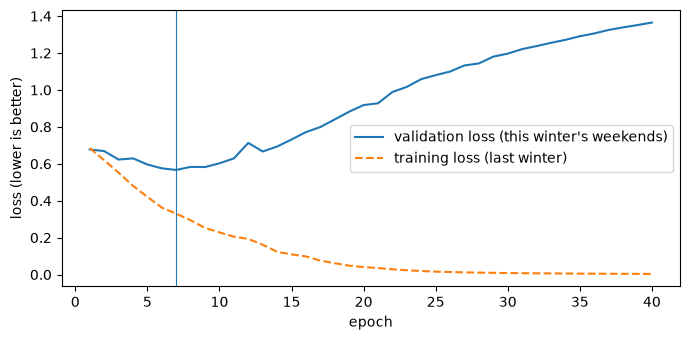

In [5]:
ep = range(1, 41)
plt.figure(figsize=(7, 3.5))
plt.plot(ep, plain["val_loss"], label="validation loss (this winter's weekends)")
plt.plot(ep, plain["train_loss"], "--", label="training loss (last winter)")
plt.axvline(best_epoch, linewidth=0.8)
plt.xlabel("epoch"); plt.ylabel("loss (lower is better)"); plt.legend(); plt.tight_layout(); plt.show()

## 6. Early stopping with a saved copy

`fit` is the code from the lesson's code screen, line for line. A new lowest validation loss saves a full copy
of the weights with `copy.deepcopy` and resets `bad` to 0; any other epoch adds 1 to `bad`; when `bad` reaches
the patience, the loop stops and the copy is loaded back. Then the cell measures the restored model again.

**Look for:** with patience 5 it stops at **epoch 12** with best 0.5667, and the restored model measures
0.5667 again: the copy worked. With patience 1 it stops at **epoch 4** and keeps epoch 3 (0.6230), because
of one wobble.

In [6]:
def fit(model, opt, patience):
    best, bad = float("inf"), 0
    for epoch in range(1, 41):
        model.train(); train_one_epoch(model, opt, epoch_seed=epoch)
        model.eval(); val_loss = measure(model, X_va, y_va)[0]
        if val_loss < best:
            best, bad = val_loss, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad == patience: break
    model.load_state_dict(best_state)
    return epoch, best

for patience in [5, 1]:
    model = make_model(0.0)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.0)
    stopped, best = fit(model, opt, patience)
    model.eval()
    after = measure(model, X_va, y_va)[0]
    print(f"patience {patience}: stopped at epoch {stopped}, best val_loss {best:.4f}, val_loss after restore {after:.4f}")

patience 5: stopped at epoch 12, best val_loss 0.5667, val_loss after restore 0.5667
patience 1: stopped at epoch 4, best val_loss 0.6230, val_loss after restore 0.6230


## 7. What dropout does to one row

The next cell takes 8 real values from the first hidden layer for one training hour and passes them through
`nn.Dropout(p=0.5)` twice in training mode, then once in eval mode.

**Look for:** in each training call some values become 0 and the others are **doubled** (multiplied by
1/(1 - p) = 2). The two training calls zero different values. In eval mode the values pass through unchanged.

In [7]:
model = make_model(0.5)
with torch.no_grad():
    h = model[1](model[0](X_tr[:1]))[0]
    hidden = h[h > 0][:8]
drop = nn.Dropout(p=0.5)
torch.manual_seed(1)
drop.train()
with torch.no_grad():
    t1 = drop(hidden)
    t2 = drop(hidden)
drop.eval()
with torch.no_grad():
    e = drop(hidden)
r = lambda t: [round(x, 4) for x in t.tolist()]
print("in:          ", r(hidden))
print("train call 1:", r(t1))
print("train call 2:", r(t2))
print("eval mode:   ", r(e))

in:           [0.1548, 0.4218, 0.4368, 0.3353, 0.4643, 0.001, 0.4896, 0.0198]
train call 1: [0.3096, 0.8437, 0.8736, 0.6705, 0.0, 0.002, 0.9793, 0.0]
train call 2: [0.0, 0.8437, 0.0, 0.6705, 0.0, 0.002, 0.9793, 0.0395]
eval mode:    [0.1548, 0.4218, 0.4368, 0.3353, 0.4643, 0.001, 0.4896, 0.0198]


## 8. Dropout left on at test time

The next cell trains the network with dropout 0.5 and weight decay 5.0 for 40 epochs. Then it scores this
winter's weekends three times **without** `model.eval()`, so dropout is still on, and twice after `model.eval()`.

**Look for:** with dropout on, three different numbers (accuracy between about 73% and 75%), and the loss is
higher every time. After `model.eval()`, the same number twice: loss 0.5179, accuracy 0.7517. No error is
raised in either case, which is why this bug is quiet.

In [8]:
model = make_model(0.5)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=5.0)
for epoch in range(1, 41):
    model.train()
    train_one_epoch(model, opt, epoch_seed=epoch)
torch.manual_seed(7)
model.train()  # the mistake: still in training mode
for k in range(3):
    loss, acc = measure(model, X_va, y_va)
    print(f"dropout on,   try {k + 1}: val_loss {loss:.4f}  val_acc {acc:.4f}")
model.eval()
for k in range(2):
    loss, acc = measure(model, X_va, y_va)
    print(f"model.eval(), try {k + 1}: val_loss {loss:.4f}  val_acc {acc:.4f}")

dropout on,   try 1: val_loss 0.5467  val_acc 0.7333
dropout on,   try 2: val_loss 0.5293  val_acc 0.7500
dropout on,   try 3: val_loss 0.5409  val_acc 0.7317
model.eval(), try 1: val_loss 0.5179  val_acc 0.7517
model.eval(), try 2: val_loss 0.5179  val_acc 0.7517


## 9. Pick a weight decay

`torch.optim.AdamW` shrinks every weight a little on each step: `w <- w - lr * weight_decay * w`. The next
cell trains the plain network five times, 40 epochs each, with five weight_decay values. It takes a little
longer than the others.

**Look for:** 5.0 gives the lowest validation loss (0.5384), with weights about half the size of no decay
(9.57 against 17.91). With 50.0 the weights almost vanish (0.36) and training accuracy drops to 0.535,
exactly the share of surge hours in last winter: the model calls surge for every hour. That is underfitting.

In [9]:
print("weight_decay  best_epoch  lowest_val_loss  last_val_loss  last_train_acc  weight_size")
sweep = {}
for wd in [0.0, 0.5, 5.0, 20.0, 50.0]:
    _, log = run(weight_decay=wd)
    sweep[wd] = log
    b = int(np.argmin(log["val_loss"]))
    print(f"{wd:12.1f}  {b + 1:10d}  {log['val_loss'][b]:15.4f}  {log['val_loss'][-1]:13.4f}  {log['train_acc'][-1]:14.4f}  {log['weight_norm']:11.2f}")

weight_decay  best_epoch  lowest_val_loss  last_val_loss  last_train_acc  weight_size


         0.0           7           0.5667         1.3650          1.0000        17.91


         0.5           7           0.5642         1.1550          1.0000        15.31


         5.0           9           0.5384         0.5778          0.9975         9.57


        20.0          11           0.5455         0.5635          0.8225         5.25


        50.0          11           0.6394         0.6943          0.5350         0.36


## 10. The four settings side by side

Plain, dropout 0.5, weight_decay 5.0, and both together, 40 epochs each, no early stopping. The plain and
weight_decay runs are reused from the cells above.

**Look for:** the plain run ends at a validation loss of 1.365, while "both" is still at its lowest at epoch 40
(0.5179). The best accuracy moves only a little (about 74% to 76%). The regularizers slow the slide into
memorising; they do not add information.

setting                   best_epoch  lowest_val_loss  val_loss@40  best_val_acc
no regularization                  7           0.5667       1.3650        0.7450
dropout 0.5                       14           0.5736       0.7131        0.7467
weight_decay 5.0                   9           0.5384       0.5778        0.7533
dropout + weight_decay            40           0.5179       0.5179        0.7567


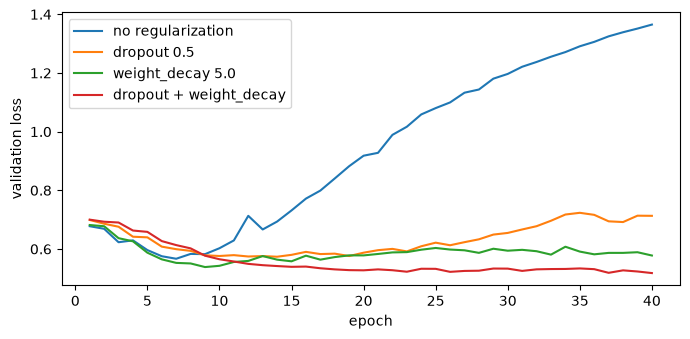

In [10]:
_, drop_log = run(p_drop=0.5)
_, both_log = run(p_drop=0.5, weight_decay=5.0)
runs = {"no regularization": plain, "dropout 0.5": drop_log, "weight_decay 5.0": sweep[5.0], "dropout + weight_decay": both_log}
print(f"{'setting':24s}  best_epoch  lowest_val_loss  val_loss@40  best_val_acc")
for name, log in runs.items():
    b = int(np.argmin(log["val_loss"]))
    print(f"{name:24s}  {b + 1:10d}  {log['val_loss'][b]:15.4f}  {log['val_loss'][-1]:11.4f}  {max(log['val_acc']):12.4f}")

plt.figure(figsize=(7, 3.5))
for name, log in runs.items():
    plt.plot(range(1, 41), log["val_loss"], label=name)
plt.xlabel("epoch"); plt.ylabel("validation loss"); plt.legend(); plt.tight_layout(); plt.show()

## 11. Broken on purpose: the best weights that were not the best

A teammate's `fit` differs on one line: `best_state = model.state_dict()`, with no copy. `state_dict()` holds
references to the live weights, so every later training step also changes the "saved best". Nothing crashes.

**Look for:** the log stops at epoch 12 and promises 0.5667. The check after the restore measures **0.7130**,
which is epoch 12's validation loss in the plain run (step 4), not the best one. The model kept the last weights.

In [11]:
def fit_broken(model, opt, patience):
    best, bad = float("inf"), 0
    for epoch in range(1, 41):
        model.train(); train_one_epoch(model, opt, epoch_seed=epoch)
        model.eval(); val_loss = measure(model, X_va, y_va)[0]
        if val_loss < best:
            best, bad = val_loss, 0
            best_state = model.state_dict()          # the bug: no copy
        else:
            bad += 1
            if bad == patience: break
        print(f"epoch {epoch:2d}  val_loss {val_loss:.4f}  best {best:.4f}  bad {bad}")
    model.load_state_dict(best_state)
    return epoch, best

model = make_model(0.0)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.0)
stopped, best = fit_broken(model, opt, 5)
print(f"stopped at epoch {stopped}, restored best weights (val_loss {best:.4f})")
model.eval()
val_loss, val_acc = measure(model, X_va, y_va)
print(f"check after restore: val_loss {val_loss:.4f}  val_acc {val_acc:.4f}")
print(f"plain run, epoch {stopped}: val_loss {plain['val_loss'][stopped - 1]:.4f}")

epoch  1  val_loss 0.6777  best 0.6777  bad 0
epoch  2  val_loss 0.6688  best 0.6688  bad 0
epoch  3  val_loss 0.6230  best 0.6230  bad 0
epoch  4  val_loss 0.6294  best 0.6230  bad 1
epoch  5  val_loss 0.5963  best 0.5963  bad 0
epoch  6  val_loss 0.5753  best 0.5753  bad 0
epoch  7  val_loss 0.5667  best 0.5667  bad 0
epoch  8  val_loss 0.5832  best 0.5667  bad 1
epoch  9  val_loss 0.5824  best 0.5667  bad 2
epoch 10  val_loss 0.6026  best 0.5667  bad 3
epoch 11  val_loss 0.6292  best 0.5667  bad 4
stopped at epoch 12, restored best weights (val_loss 0.5667)
check after restore: val_loss 0.7130  val_acc 0.7300
plain run, epoch 12: val_loss 0.7130


## Now change it

Three small experiments. In each cell, edit only the line marked `# <- change this`, then run the cell.

**Experiment 1: patience.** Set `PATIENCE` to 2 or 3. With patience 2 the wobble at epoch 4 no longer stops
training, so it should reach the epoch-7 weights and stop at epoch 9. Patience 3 also finds epoch 7 and stops
at epoch 10: one more epoch paid for nothing.

In [12]:
PATIENCE = 2  # <- change this
model = make_model(0.0)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.0)
stopped, best = fit(model, opt, PATIENCE)
model.eval()
print(f"patience {PATIENCE}: stopped at epoch {stopped}, best val_loss {best:.4f}, after restore {measure(model, X_va, y_va)[0]:.4f}")

patience 2: stopped at epoch 9, best val_loss 0.5667, after restore 0.5667


**Experiment 2: dropout strength.** Set `P_DROP` to 0.2, then 0.8, and compare with 0.5 in step 10
(best epoch 14, val_loss@40 0.7131). With 0.2 the network slides into memorising almost like the plain one:
best at epoch 7 and about 1.2 by epoch 40. With 0.8 it learns so slowly that it is still at its best at
epoch 40, and training accuracy stays below 0.9. Stronger dropout means more epochs.

In [13]:
P_DROP = 0.2  # <- change this
_, log = run(p_drop=P_DROP)
b = int(np.argmin(log["val_loss"]))
print(f"dropout {P_DROP}: best epoch {b + 1}, lowest val_loss {log['val_loss'][b]:.4f}, "
      f"val_loss@40 {log['val_loss'][-1]:.4f}, train_acc@40 {log['train_acc'][-1]:.3f}")

dropout 0.2: best epoch 7, lowest val_loss 0.5627, val_loss@40 1.2151, train_acc@40 1.000


**Experiment 3: the edge of underfitting.** Set `WD` to 30, then 40, then 45. Somewhere between 20 and 50
the weights get too small to fit last winter. Watch training accuracy: about 0.81 at 30, about 0.63 at 40,
and at 45 it falls to 0.535, the surge share: the model has given up and calls surge for every hour.

In [14]:
WD = 30.0  # <- change this
_, log = run(weight_decay=WD)
b = int(np.argmin(log["val_loss"]))
print(f"weight_decay {WD}: lowest val_loss {log['val_loss'][b]:.4f}, train_acc@40 {log['train_acc'][-1]:.3f}, "
      f"val_acc@40 {log['val_acc'][-1]:.3f}, weight size {log['weight_norm']:.2f}")

weight_decay 30.0: lowest val_loss 0.5773, train_acc@40 0.808, val_acc@40 0.685, weight size 4.09


## What you should see

The same checklist as the lesson's last screen. Your numbers may differ slightly with another PyTorch version.

- In the plain run (step 4), training loss falls on every epoch and ends near 0.003, while validation loss is
  lowest around epoch 7 and passes 1.3 by epoch 40.
- Early stopping with patience 5 (step 6) stops at epoch 12, and the restored model scores the same validation
  loss as its best epoch.
- Scoring the dropout network three times in training mode (step 8) prints three different numbers; after
  model.eval(), the same number twice.
- With weight_decay 50.0 (step 9), training accuracy drops to about the share of surge hours: the model calls
  surge everywhere.
- The broken loop (step 11, state_dict without a copy) restores a validation loss that matches the stop epoch,
  not the best one.